# Nonlinear Clustering / So sánh các thuật toán phân cụm

**Bài toán / Problem:** so sánh K-Means, Gaussian Mixture và Spectral Clustering khi dữ liệu có dạng vòng tròn hoặc hai vầng trăng.
**Input:** tập điểm hai chiều mô phỏng (`make_circles`, `make_moons`).
**Output:** nhãn cụm, biểu đồ và Adjusted Rand Index (ARI) dùng nhãn thật để đánh giá.
**Điều tôi học / Lesson:** giả định hình học của thuật toán quan trọng hơn việc chọn mô hình theo tên; Spectral có thể phù hợp hơn với cụm phi tuyến.
**Run:** Python/Colab với NumPy, SciPy, Matplotlib và scikit-learn; chạy cell theo thứ tự.

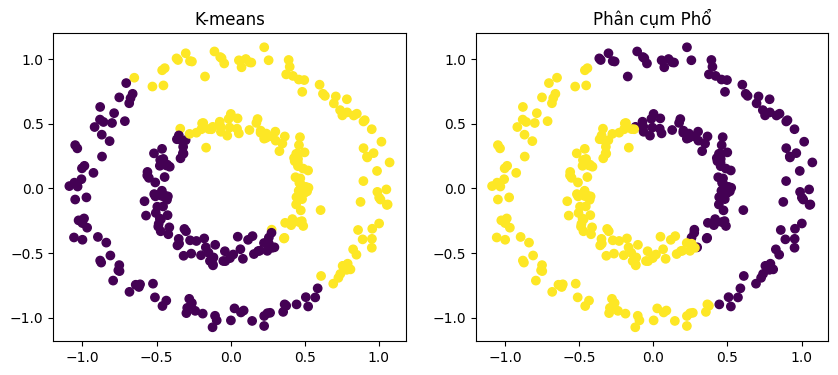

In [1]:
from sklearn.datasets import make_circles
from sklearn.cluster import KMeans, SpectralClustering
import matplotlib.pyplot as plt

# Tạo dữ liệu vòng tròn
X, y = make_circles(n_samples=300, factor=0.5, noise=0.05, random_state=0)

# K-means
kmeans = KMeans(n_clusters=2, random_state=0, n_init=10).fit(X)

# Spectral Clustering với Gaussian similarity (RBF kernel)
spectral = SpectralClustering(
    n_clusters=2,
    affinity='rbf',  # sử dụng Gaussian kernel
    gamma=15,        # gamma ~ 1 / (2*sigma^2)
    random_state=0
).fit(X)

# Hiển thị kết quả
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(X[:, 0], X[:, 1], c=kmeans.labels_, cmap='viridis')
ax[0].set_title('K-means')
ax[1].scatter(X[:, 0], X[:, 1], c=spectral.labels_, cmap='viridis')
ax[1].set_title('Phân cụm Phổ')
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

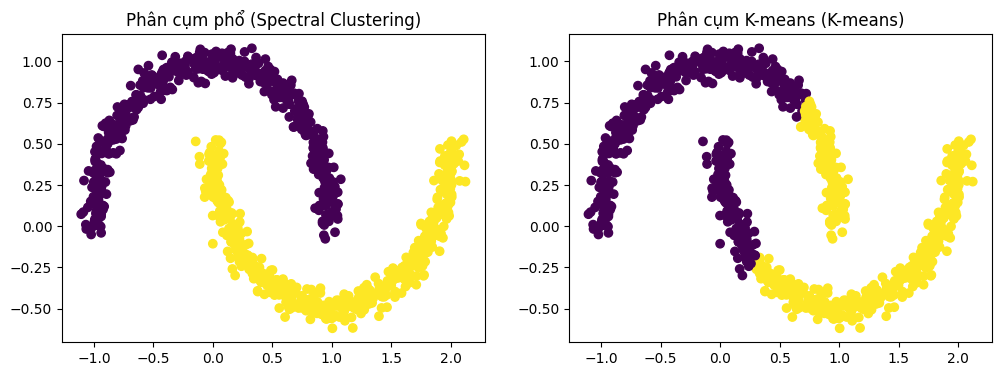

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import SpectralClustering, KMeans

# Bước 1: Tạo dữ liệu hai vầng trăng
X, _ = make_moons(n_samples=1000, noise=0.05, random_state=42)

# Bước 2: Phân cụm phổ (Spectral Clustering)
sc = SpectralClustering(n_clusters=2, affinity='rbf', gamma=100, random_state=42)
labels_sc = sc.fit_predict(X)

# Bước 3: Phân cụm K-means (K-means)
km = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_km = km.fit_predict(X)

# Bước 4: Vẽ kết quả
plt.figure(figsize=(12, 4))
plt.subplot(121)
plt.scatter(X[:, 0], X[:, 1], c=labels_sc, cmap='viridis')
plt.title('Phân cụm phổ (Spectral Clustering)')
plt.subplot(122)
plt.scatter(X[:, 0], X[:, 1], c=labels_km, cmap='viridis')
plt.title('Phân cụm K-means (K-means)')
plt.show()

K-Means: Adjusted Rand Index = 0.2393
Gaussian Mixture: Adjusted Rand Index = 0.4979
Spectral: Adjusted Rand Index = 1.0000


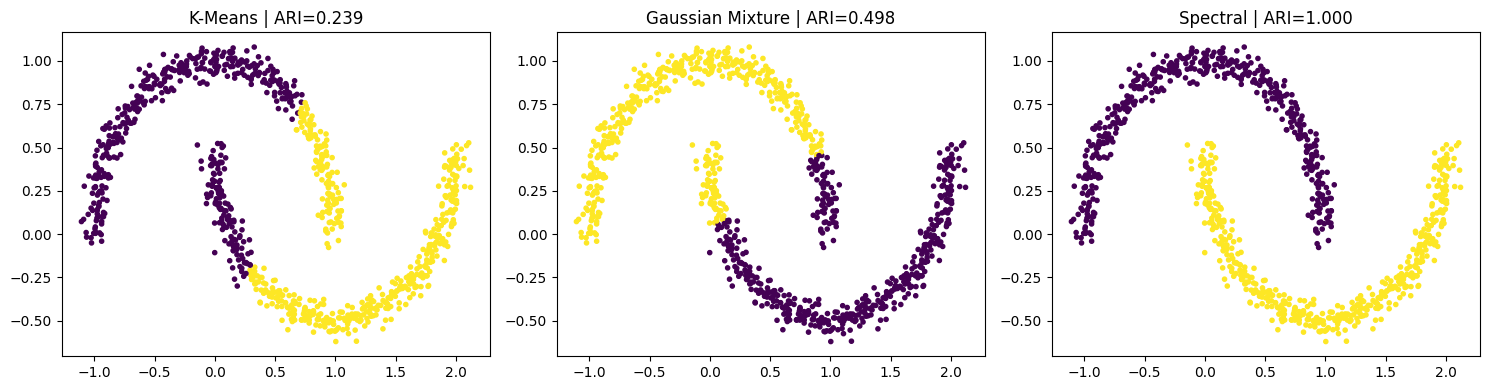

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import SpectralClustering, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

# Synthetic labels are used only for evaluation / Nhãn thật chỉ dùng để đánh giá
X, y_true = make_moons(n_samples=1000, noise=0.05, random_state=42)

models = {
    "K-Means": KMeans(n_clusters=2, random_state=42, n_init=10),
    "Gaussian Mixture": GaussianMixture(n_components=2, random_state=42),
    "Spectral": SpectralClustering(n_clusters=2, affinity="rbf", gamma=100, random_state=42),
}

LAB_RESULT = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    labels = model.fit_predict(X)
    ari = adjusted_rand_score(y_true, labels)
    LAB_RESULT[name] = float(ari)
    assert np.isfinite(ari) and -1 <= ari <= 1
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=9)
    ax.set_title(f"{name} | ARI={ari:.3f}")
    print(f"{name}: Adjusted Rand Index = {ari:.4f}")

plt.tight_layout()
plt.show()


**Điều rút ra / What I learned:** ARI dùng nhãn mô phỏng chỉ để đánh giá sau khi phân cụm.
Tham số `gamma` phụ thuộc hình học và thang đo dữ liệu; kết quả tốt trên hai vầng trăng
chưa cho biết mô hình nào phù hợp với một tập dữ liệu khác.

Synthetic labels are used only for evaluation. Kernel scale matters; these examples
illustrate geometric assumptions rather than a general ranking of algorithms.